<a href="https://colab.research.google.com/github/echieugbekile-wq/customer-spending-analysis/blob/main/customer_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd

# Load the dataset using the correct path
df = pd.read_csv("/Customers.csv")
df_clean = df.copy()

# Standardize column names
df_clean.columns = ["customer_id", "gender", "age", "income", "spending_score", "profession", "work_experience", "family_size"]

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Handle missing values and empty whitespaces in 'profession'
df_clean["profession"] = (
    df_clean["profession"]
    .replace(r"^\s*$", pd.NA, regex=True)
    .fillna("Unknown")
)

# Filter out invalid ages (age == 0)
df_clean = df_clean[df_clean["age"] > 0]

# Filter out rows where income or spending_score is 0
df_clean = df_clean[(df_clean["income"] > 0) & (df_clean["spending_score"] > 0)]



# Display cleaned dataframe info and summary statistics
print(df_clean.info())
display(df_clean.describe())

df_clean.sort_values("income").head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 1972 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   customer_id      1972 non-null   int64 
 1   gender           1972 non-null   object
 2   age              1972 non-null   int64 
 3   income           1972 non-null   int64 
 4   spending_score   1972 non-null   int64 
 5   profession       1972 non-null   object
 6   work_experience  1972 non-null   int64 
 7   family_size      1972 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 138.7+ KB
None


,customer_id,age,income,spending_score,work_experience,family_size
count,1972.000000,1972.000000,1972.000000,1972.000000,1972.000000,1972.000000
mean,1001.676978,49.574037,110838.659229,50.922921,4.108012,3.763185
std,577.013422,28.076942,45658.013613,27.873130,3.920829,1.967056
min,1.000000,1.000000,1000.000000,1.000000,0.000000,1.000000
25%,503.750000,26.000000,74856.750000,28.000000,1.000000,2.000000
50%,1004.500000,49.000000,109827.000000,50.000000,3.000000,4.000000
75%,1499.250000,74.000000,149257.250000,75.000000,7.000000,5.000000
max,2000.000000,99.000000,189974.000000,100.000000,17.000000,9.000000


,customer_id,gender,age,income,spending_score,profession,work_experience,family_size
272,273,Female,96,1000,76,Entertainment,0,3
96,97,Female,47,2000,47,Artist,0,1
113,114,Male,19,2000,46,Artist,1,1
233,234,Female,78,3000,14,Healthcare,0,4
45,46,Female,24,3000,65,Lawyer,4,2
252,253,Female,78,3000,14,Artist,5,4
66,67,Female,43,3000,50,Doctor,0,2
101,102,Female,49,4000,48,Executive,1,7
244,245,Female,53,4000,20,Artist,0,4
21,22,Male,25,4000,73,Healthcare,3,4


In [27]:
df_clean.groupby("gender")["spending_score"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
gender,,,
Female,1168,51.1,50.0
Male,804,50.6,50.0


In [28]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 17, 29, 44, 59, 100],
    labels=["Under 18", "18-29", "30-44", "45-59", "60+"]
)

df_clean.groupby("age_group", observed=True)["spending_score"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
age_group,,,
Under 18,307,54.2,58.0
18-29,258,51.8,51.5
30-44,337,49.6,48.0
45-59,300,49.9,49.0
60+,770,50.3,50.0


In [29]:
(df_clean.groupby("profession")["spending_score"]
    .agg(["count", "mean", "median"])
    .round(1)
    .sort_values("mean", ascending=False))

,count,mean,median
profession,,,
Entertainment,231,52.9,53.0
Artist,606,52.4,52.0
Doctor,156,51.0,48.5
Healthcare,338,50.5,51.0
Executive,152,50.1,49.5
Engineer,175,49.7,48.0
Marketing,81,49.6,47.0
Lawyer,139,48.9,49.0
Homemaker,60,46.4,45.5


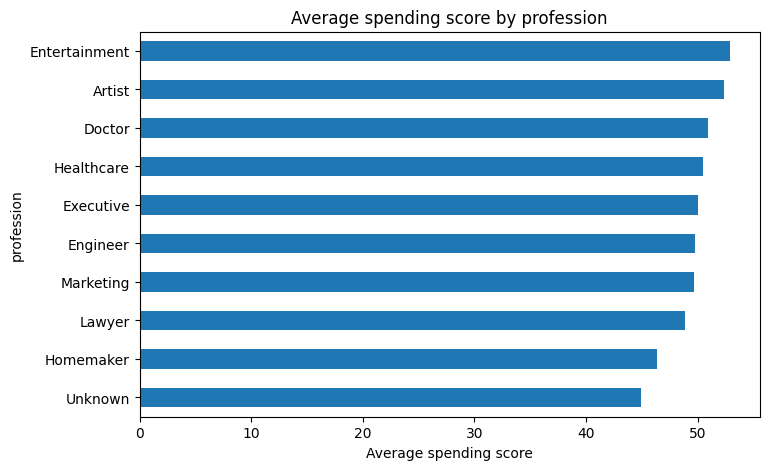

In [30]:
import matplotlib.pyplot as plt

avg = df_clean.groupby("profession")["spending_score"].mean().sort_values()
avg.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Average spending score")
plt.title("Average spending score by profession")
plt.show()

In [31]:
from scipy import stats

# Gender: t-test
female = df_clean[df_clean["gender"] == "Female"]["spending_score"]
male = df_clean[df_clean["gender"] == "Male"]["spending_score"]
print(stats.ttest_ind(female, male, equal_var=False))

# Age group: ANOVA
groups = [g["spending_score"] for _, g in df_clean.groupby("age_group", observed=True)]
print(stats.f_oneway(*groups))

# Profession: ANOVA
groups = [g["spending_score"] for _, g in df_clean.groupby("profession")]
print(stats.f_oneway(*groups))

# Under 18 vs everyone else
u18 = df_clean[df_clean["age"] < 18]["spending_score"]
adults = df_clean[df_clean["age"] >= 18]["spending_score"]
print(stats.ttest_ind(u18, adults, equal_var=False))

TtestResult(statistic=np.float64(0.38200439758660215), pvalue=np.float64(0.7025048599606886), df=np.float64(1735.9374990925494))
F_onewayResult(statistic=np.float64(1.519985688191795), pvalue=np.float64(0.1937151312306394))
F_onewayResult(statistic=np.float64(0.8332869231759927), pvalue=np.float64(0.5853504178404605))
TtestResult(statistic=np.float64(2.1965468358630127), pvalue=np.float64(0.028600337713301203), df=np.float64(418.6925333540065))


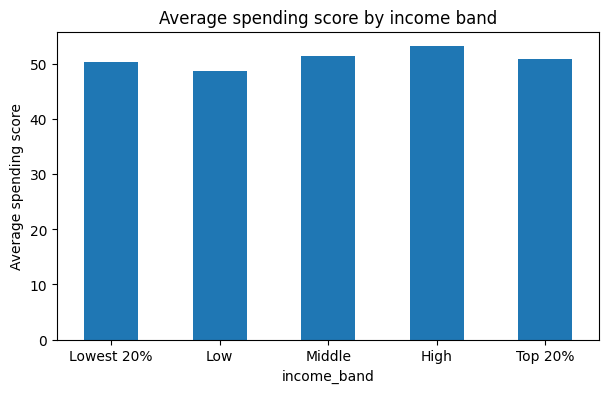

In [33]:
df_clean["income_band"] = pd.qcut(df_clean["income"], 5, labels=["Lowest 20%", "Low", "Middle", "High", "Top 20%"])

df_clean.groupby("income_band", observed=True)["spending_score"].mean().plot(kind="bar", figsize=(7, 4))
plt.ylabel("Average spending score")
plt.title("Average spending score by income band")
plt.xticks(rotation=0)
plt.show()